# mounting

In [1]:
# from google.colab import drive
# drive.mount('/content/drive')

# importing libraries

In [2]:
import os
import cv2
import numpy as np
from sklearn.model_selection import train_test_split
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.layers import Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping
from sklearn.metrics import classification_report, accuracy_score
from sklearn.metrics import confusion_matrix
import seaborn as sns
from collections import Counter

# directory

In [3]:
dataset_path = r'C:\Users\T2410211\Desktop\DENSE121_noisy'

class_folders = ['cerebral_infarct', 'cortical_atrophy', 'ischemic_changes', 'lipoma', 'normal']

# Preprocess the Images

In [4]:
# Function to preprocess images and ensure consistent shape
def preprocess_images(directory, target_size=(224, 224)):
    images = []
    labels = []

    class_folders = ['cerebral_infarct', 'cortical_atrophy', 'ischemic_changes', 'lipoma', 'normal']

    for class_name in class_folders:
        class_dir = os.path.join(directory, class_name)
        if os.path.isdir(class_dir):
            for img_name in os.listdir(class_dir):
                img_path = os.path.join(class_dir, img_name)
                if os.path.isfile(img_path):
                    img = cv2.imread(img_path, cv2.IMREAD_UNCHANGED)
                    if img is not None:
                        img = cv2.resize(img, target_size)

                        # Convert grayscale to RGB if necessary
                        if len(img.shape) == 2:  # Grayscale image
                            img = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)

                        # Normalize and ensure shape is (224, 224, 3)
                        img = img / 255.0
                        if img.shape == (224, 224, 3):
                            images.append(img)
                            labels.append(class_name)

    print(f"Total images loaded: {len(images)}")
    return np.array(images), np.array(labels)

In [5]:
# Preprocess all images
X, y = preprocess_images(dataset_path)

# Check if images are loaded correctly
print(f"Number of images loaded: {len(X)}")
print(f"Shape of input data: {X.shape}")

Total images loaded: 2706
Number of images loaded: 2706
Shape of input data: (2706, 224, 224, 3)


# Split Data and Encode Labels

In [6]:
# Step 1: Stratified split into 80% train_val and 20% test
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Step 2: Stratified split into 80% train and 20% val
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.2, random_state=42, stratify=y_train_val)

# Step 3: Oversample small classes in the training set
X_stack = list(zip(X_train, y_train))
augmented_X = []
augmented_y = []
target_count = 500

for class_name in np.unique(y_train):
    class_samples = [pair for pair in X_stack if pair[1] == class_name]
    count = len(class_samples)

    if count < target_count:
        needed = target_count - count
        reps = needed // count + 1
        oversampled = (class_samples * reps)[:needed]
        augmented_X.extend([x for x, _ in oversampled])
        augmented_y.extend([y for _, y in oversampled])

X_train_balanced = np.concatenate((X_train, np.array(augmented_X)), axis=0)
y_train_balanced = np.concatenate((y_train, np.array(augmented_y)), axis=0)

from collections import Counter
print("Balanced training distribution:", Counter(y_train_balanced))

# Step 4: Encode the class labels
encoder = LabelEncoder()
encoder.fit(['cerebral_infarct', 'cortical_atrophy', 'ischemic_changes', 'lipoma', 'normal'])

# ✅ Use the balanced labels for training!
y_train_balanced_encoded = encoder.transform(y_train_balanced)
y_val_encoded = encoder.transform(y_val)
y_test_encoded = encoder.transform(y_test)

# Step 5: One-hot encode all sets
y_train_categorical = to_categorical(y_train_balanced_encoded, num_classes=5)
y_val_categorical = to_categorical(y_val_encoded, num_classes=5)
y_test_categorical = to_categorical(y_test_encoded, num_classes=5)

# Step 6: Check shapes
print(f"Balanced Training set: {X_train_balanced.shape}")
print(f"Validation set: {X_val.shape}")
print(f"Test set: {X_test.shape}")


Balanced training distribution: Counter({np.str_('normal'): 817, np.str_('cerebral_infarct'): 500, np.str_('ischemic_changes'): 500, np.str_('lipoma'): 500, np.str_('cortical_atrophy'): 500})
Balanced Training set: (2817, 224, 224, 3)
Validation set: (433, 224, 224, 3)
Test set: (542, 224, 224, 3)


# building and compiling the DenseNet121 model.

In [ ]:
# Load the DenseNet121 model without the top layers (include_top=False)
base_model = DenseNet121(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# Freezing the base model so the pre-trained layers won't be updated during training
base_model.trainable = False

# Adding custom layers on top of the DenseNet121 base
model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(1024, activation='relu'),
    Dropout(0.5),  # Dropout regularization layer with 50% drop rate
    Dense(5, activation='softmax')  # Final output layer for 5 classes
])

# Compile the model with the same settings
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

: 

# training the model.
early stopping

ReduceLROnPlateau

In [ ]:
# Reduce learning rate when the validation loss plateaus
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,  # Reduce the learning rate by half when triggered
    patience=2,  # Wait for 2 epochs without improvement before reducing learning rate
    min_lr=0.00001  # Minimum learning rate
)

# Early stopping to prevent overfitting
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,  # Stop training after 5 epochs without improvement
    restore_best_weights=True  # Restore the best model weights after stopping
)

# Train the model with both EarlyStopping and ReduceLROnPlateau
history = model.fit(
    X_train_balanced, y_train_categorical, 
    validation_data=(X_val, y_val_categorical),
    epochs=50,
    batch_size=16,
    callbacks=[early_stopping, reduce_lr]
)

Epoch 1/50
 53/177 ━━━━━━━━━━━━━━━━━━━━ 17s 138ms/step - accuracy: 0.4692 - loss: 1.6679

# plotting the training and validation accuracy and loss.

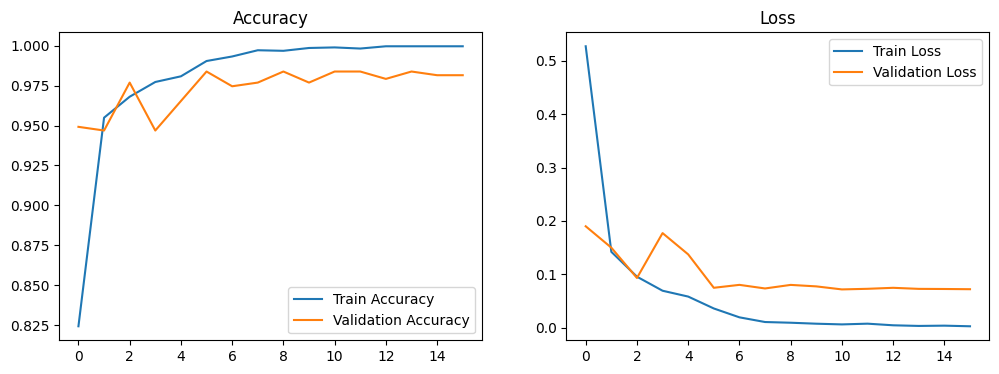

In [ ]:
# Plot training & validation accuracy and loss
plt.figure(figsize=(12, 4))

# Plot accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy')
plt.legend()

# Plot loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss')
plt.legend()

plt.show()

# Evaluate the Model on the Test Set:

In [ ]:
# Evaluate the model on the test set
test_loss, test_accuracy = model.evaluate(X_test, y_test_categorical)

print(f"Test Loss: {test_loss}")
print(f"Test Accuracy: {test_accuracy}")

17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 290ms/step - accuracy: 0.9934 - loss: 0.0310
Test Loss: 0.04869283363223076
Test Accuracy: 0.9870848655700684


17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 280ms/step - accuracy: 0.9934 - loss: 0.0310


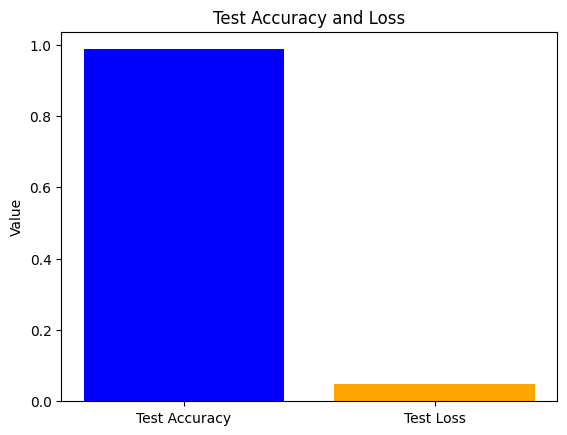

Test Loss: 0.04869283363223076
Test Accuracy: 0.9870848655700684


In [ ]:
# Evaluate the model on the test set
test_loss, test_accuracy = model.evaluate(X_test, y_test_categorical)

# Visualize the test accuracy and loss
labels = ['Test Accuracy', 'Test Loss']
values = [test_accuracy, test_loss]

plt.bar(labels, values, color=['blue', 'orange'])
plt.title('Test Accuracy and Loss')
plt.ylabel('Value')
plt.show()

print(f"Test Loss: {test_loss}")
print(f"Test Accuracy: {test_accuracy}")

# Saving the model

In [ ]:
# Save the model to Google Drive
# model.save('/trained.keras')

# Analysing results

making predictions on validation set

In [ ]:
# Make predictions on the test set
y_test_pred = model.predict(X_test)

# Convert the predictions from one-hot encoded to class labels
y_test_pred_classes = np.argmax(y_test_pred, axis=1)

# Convert the true test labels (one-hot encoded) to class labels
y_test_true_classes = np.argmax(y_test_categorical, axis=1)

# Check the shapes of predicted and true classes
print(f"Predicted Classes Shape: {y_test_pred_classes.shape}")
print(f"True Classes Shape: {y_test_true_classes.shape}")

17/17 ━━━━━━━━━━━━━━━━━━━━ 7s 363ms/step
Predicted Classes Shape: (542,)
True Classes Shape: (542,)


**Precision, Recall, F1 Score, and Other Metrics**

In [ ]:
# Generate the classification report for the test set
class_report_test = classification_report(y_test_true_classes, y_test_pred_classes,
                                          target_names=['cerebral_infarct', 'cortical_atrophy', 'ischemic_changes', 'lipoma', 'normal'])

# Print the classification report
print("Test Set Classification Report:\n", class_report_test)

Test Set Classification Report:
                   precision    recall  f1-score   support

cerebral_infarct       0.98      0.99      0.99       141
cortical_atrophy       0.92      0.79      0.85        14
ischemic_changes       1.00      1.00      1.00         2
          lipoma       0.98      0.99      0.99       129
          normal       1.00      0.99      0.99       256

        accuracy                           0.99       542
       macro avg       0.98      0.95      0.96       542
    weighted avg       0.99      0.99      0.99       542



**Visualising precision, recall and f1 score**

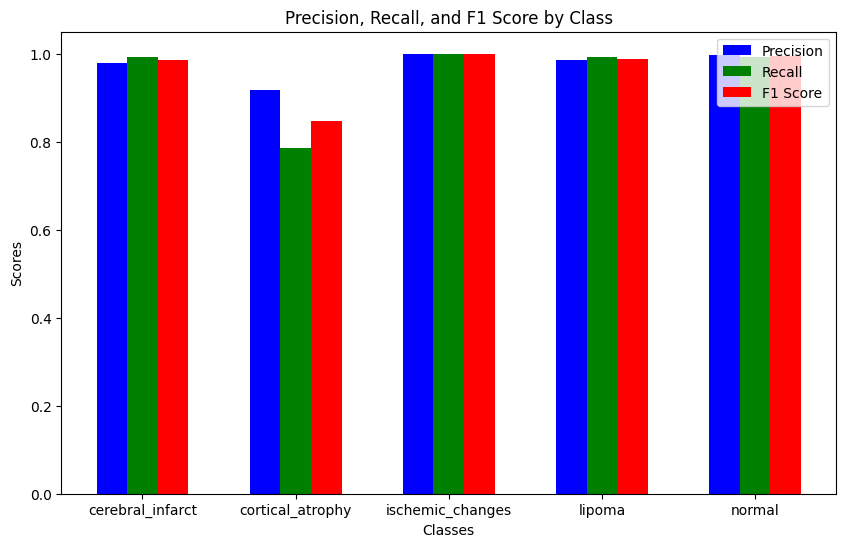

In [ ]:
# Generate the classification report
class_report_test = classification_report(y_test_true_classes, y_test_pred_classes,
                                          target_names=['cerebral_infarct', 'cortical_atrophy', 'ischemic_changes', 'lipoma', 'normal'],
                                          output_dict=True)

# Extract precision, recall, and F1-score for each class
classes = ['cerebral_infarct', 'cortical_atrophy', 'ischemic_changes', 'lipoma', 'normal']
precision = [class_report_test[cls]['precision'] for cls in classes]
recall = [class_report_test[cls]['recall'] for cls in classes]
f1_score = [class_report_test[cls]['f1-score'] for cls in classes]

# Create a bar chart for precision, recall, and F1 score
x = np.arange(len(classes))  # the label locations
width = 0.2  # width of the bars

fig, ax = plt.subplots(figsize=(10, 6))

# Plotting the bars for precision, recall, and f1-score
rects1 = ax.bar(x - width, precision, width, label='Precision', color='b')
rects2 = ax.bar(x, recall, width, label='Recall', color='g')
rects3 = ax.bar(x + width, f1_score, width, label='F1 Score', color='r')

# Add some text for labels, title, and custom x-axis tick labels, etc.
ax.set_xlabel('Classes')
ax.set_ylabel('Scores')
ax.set_title('Precision, Recall, and F1 Score by Class')
ax.set_xticks(x)
ax.set_xticklabels(classes)
ax.legend()

# Display the chart
plt.show()

 **confusion matrix**

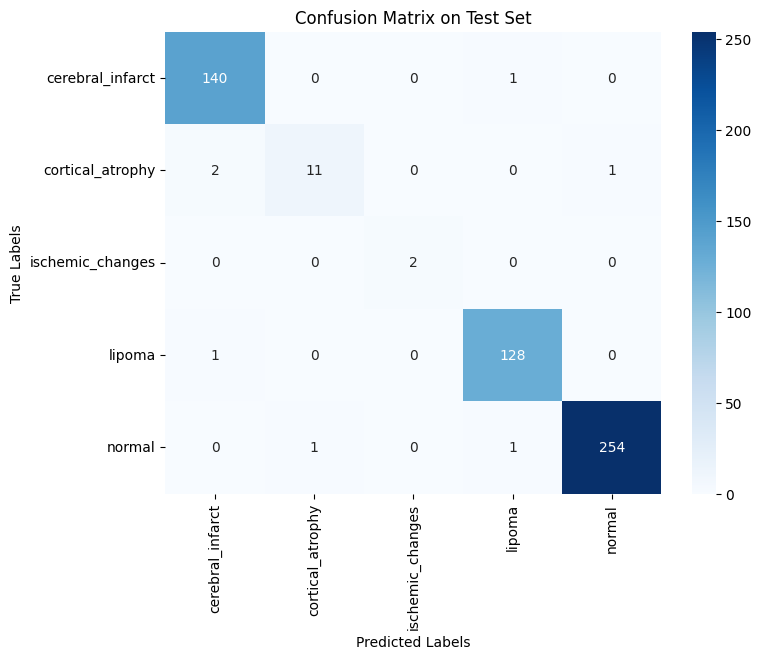

In [ ]:
# Generate the confusion matrix
conf_matrix_test = confusion_matrix(y_test_true_classes, y_test_pred_classes)

# Create a heatmap for the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_test, annot=True, fmt='d', cmap='Blues',
            xticklabels=['cerebral_infarct', 'cortical_atrophy', 'ischemic_changes', 'lipoma', 'normal'],
            yticklabels=['cerebral_infarct', 'cortical_atrophy', 'ischemic_changes', 'lipoma', 'normal'])
plt.title('Confusion Matrix on Test Set')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

**Identify Misclassified Instances**

In [ ]:
# Find the misclassified indices
misclassified_indices = np.where(y_test_true_classes != y_test_pred_classes)[0]

# Print information about misclassified instances
print(f"Number of misclassified instances: {len(misclassified_indices)}")

for idx in misclassified_indices:
    print(f"Instance {idx}: True Class = {y_test_true_classes[idx]}, Predicted Class = {y_test_pred_classes[idx]}")


Number of misclassified instances: 7
Instance 132: True Class = 1, Predicted Class = 4
Instance 267: True Class = 1, Predicted Class = 0
Instance 325: True Class = 1, Predicted Class = 0
Instance 339: True Class = 0, Predicted Class = 3
Instance 450: True Class = 4, Predicted Class = 3
Instance 534: True Class = 4, Predicted Class = 1
Instance 537: True Class = 3, Predicted Class = 0


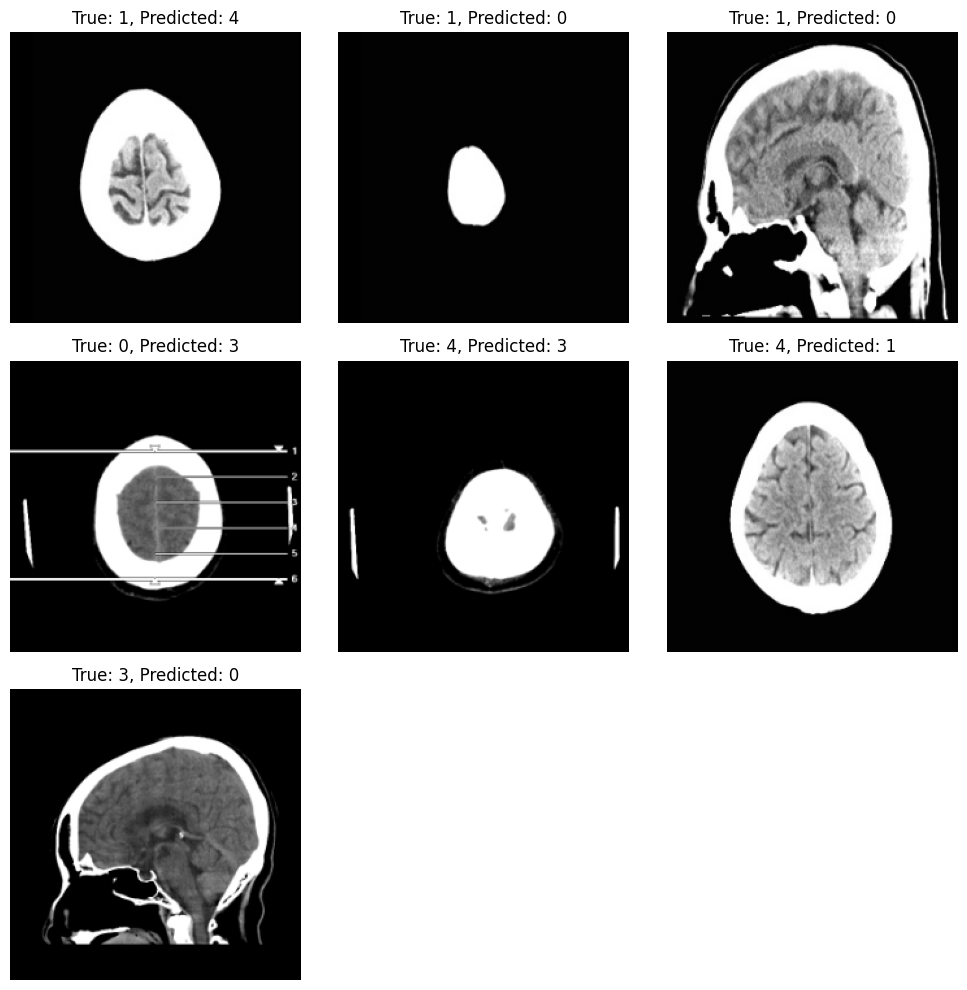

In [ ]:
# Assuming X_test contains image data
num_misclassified = len(misclassified_indices)
plt.figure(figsize=(10, 10))

for i, idx in enumerate(misclassified_indices[:9]):  # Show the first 9 misclassified instances
    plt.subplot(3, 3, i + 1)
    plt.imshow(X_test[idx])  # Adjust this if the images are preprocessed (e.g., normalized)
    plt.title(f"True: {y_test_true_classes[idx]}, Predicted: {y_test_pred_classes[idx]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

# saving the model

In [ ]:
# # Save the model to Google Drive
# model.save('/content/drive/MyDrive/thesis_repository/code/DenseNet_training_set/trained.keras')